# AI6101 — Q-learning for CliffBoxPushing
**Name:** YourName · **Matriculation number:** YourMatriculationNumber

This project trains a tabular Q-learning agent to push the box to the goal. The experiments examine learning progress, the learned value function and policy, action-noise robustness, exploration strategies, and hierarchical learning with sparse rewards.

In [1]:
from pathlib import Path
import copy
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline

OUTPUT_DIR = Path('results')
OUTPUT_DIR.mkdir(exist_ok=True)


## 1. Grid World and State Representation
The environment contains 6 rows and 14 columns. The agent starts at `(4,1)`, the box at `(1,1)`, and the goal is `(4,13)`. Actions 1–4 correspond to up, down, left, and right.

Each state contains both positions:

$$s=(a_r,a_c,b_r,b_c).$$

The Q-table contains $84^2=7,056$ Cartesian states and four actions per state, giving 28,224 entries.

After each transition, the original reward is

$$r=-1-d_1(A,B)-d_1(B,G)-1000\mathbb{1}_{\mathrm{cliff}}+1000\mathbb{1}_{\mathrm{goal}},$$

where $d_1$ is Manhattan distance. An episode ends when the agent or box enters a cliff, the box reaches the goal, or 100 primitive steps have been executed. The box is restricted to rows 1–4 and columns 1–13; the agent can use the outer rows and columns to reposition.

In [2]:
"""Original supplied environment, unchanged (template code cell 2)."""
from typing import List, Tuple
import copy
import numpy as np

AGENT = 'A'
BOX = 'B'
GOAL = 'G'
DANGER = 'x'
GRID = '_'


class CliffBoxGridWorld:
    """
    Cliff Box Pushing Grid World.
    """
    action_space = [1, 2, 3, 4]
    forces = {
        1: np.array([-1, 0]),
        2: np.array([1,  0]),
        3: np.array([0, -1]),
        4: np.array([0,  1]),
    }
    world_width = 14
    world_height = 6
    goal_pos = np.array([4, 13])
    init_agent_pos = np.array([4, 1])
    init_box_pos = np.array([1, 1])
    danger_region = [
        [(0, 3), (3, 3)],
        [(5, 3), (5, 3)],
        [(4, 6), (5, 6)],
        [(2, 7), (3, 7)],
        [(0, 11), (0, 11)],
        [(3, 11), (5, 11)],
        [(0, 12), (0, 12)],
        [(3, 12), (4, 12)],
    ]

    def __init__(self,
                 episode_length=100,
                 render=False,
                 ):
        """
        The grid world looks like:
        ____________________________________________________________
        |___|_0_|_1_|_2_|_3_|_4_|_5_|_6_|_7_|_8_|_9_|_10|_11|_12|_13|
        |_0_|___|___|___|_x_|___|___|___|___|___|___|___|_x_|_x_|___|
        |_1_|___|_B_|___|_x_|___|___|___|___|___|___|___|___|___|___|
        |_2_|___|___|___|_x_|___|___|___|_x_|___|___|___|___|___|___|
        |_3_|___|___|___|_x_|___|___|___|_x_|___|___|___|_x_|_x_|___|
        |_4_|___|_A_|___|___|___|___|_x_|___|___|___|___|_x_|_x_|_G_|
        |_5_|___|___|___|_x_|___|___|_x_|___|___|___|___|_x_|___|___|
        """
        # Environment configurations.
        self.episode_length = episode_length
        self.render = render
        self.agent_pos = self.init_agent_pos
        self.box_pos = self.init_box_pos

        # Visualization.
        if self.render:
            self.world = np.chararray((self.world_height, self.world_width))
            self.last_agent_pos = copy.deepcopy(self.agent_pos)
            self.last_box_pos = copy.deepcopy(self.box_pos)
            self.world[:] = GRID
            for region in self.danger_region:
                A, B = region
                assert A[1] == B[1], "A[1] != B[1]"
                self.world[A[0]:B[0]+1, A[1]] = DANGER
            self.world[self.agent_pos[0], self.agent_pos[1]] = AGENT
            self.world[self.box_pos[0], self.box_pos[1]] = BOX
            self.world[self.goal_pos[0], self.goal_pos[1]] = GOAL

    def reset(self):
        """
        Resets the environment.

        Returns:
            The initial state (agent position and box position).
        """
        self.timesteps = 0
        self.action_history = []
        self.agent_pos = self.init_agent_pos
        self.box_pos = self.init_box_pos

        return tuple([*self.agent_pos.tolist(), *self.box_pos.tolist()])

    def step(self, actions: int):
        """ 
        Args: actions (a list of int).

        Returns:
            The next state, reward, done, info.
        """
        self.action_history.append(actions)

        # Update the state.
        force = self.forces[actions]
        # check if the agent is near the box
        if np.sum(np.abs(self.agent_pos - self.box_pos)) == 1:
            # check if box is moved
            if all(self.agent_pos + force == self.box_pos):
                # check out of boundary
                self.box_pos = self._check_pos_boundary(pos=self.box_pos + force, box_hard_boundary=True)
        # move the agent
        new_agent_pos = self._check_pos_boundary(self.agent_pos + force)
        if not all(new_agent_pos == self.box_pos):
            self.agent_pos = new_agent_pos
        state = tuple([*self.agent_pos.tolist(), *self.box_pos.tolist()])

        # Calculate the rewards
        done = self.timesteps == self.episode_length - 1
        # the distance between agents and box
        dist = np.sum(np.abs(self.agent_pos - self.box_pos))
        reward = -1  # -1 for each step
        reward -= dist
        # if agents or box is off the cliff
        if self._check_off_cliff(self.agent_pos) or self._check_off_cliff(self.box_pos):
            reward += -1000
            done = True
        
        if all(self.box_pos == self.goal_pos):
            reward += 1000
            done = True
        
        reward -= np.sum(np.abs(self.box_pos - self.goal_pos))

        if self.render:
            self._update_render()

        self.timesteps += 1
        info = {}

        return state, reward, done, info

    def print_world(self):
        """
        Render the world in the command line.
        """
        if len(self.action_history) > 0:
            print(f'Action: {self.action_history[-1]}')
        print(self.world)

    def _check_pos_boundary(self, pos, box_hard_boundary: bool = False):
        """
        Move the given position within the world bound.
        """
        if pos[0] < 0:
            pos[0] = 0
        if pos[0] >= self.world_height:
            pos[0] = self.world_height - 1
        if pos[1] < 0:
            pos[1] = 0
        if pos[1] >= self.world_width:
            pos[1] = self.world_width - 1
        
        if box_hard_boundary:
            if pos[0] == 0:
                pos[0] += 1
            elif pos[0] == self.world_height - 1:
                pos[0] = self.world_height - 2
            if pos[1] == 0:
                pos[1] += 1
                    
        return pos

    def _check_off_cliff(self, pos):
        """
        Check if the given position is off cliff.
        """
        for region in self.danger_region:
            A, B = region
            assert A[1] == B[1], "A[1] != B[1]"
            if A[0] <= pos[0] <= B[0] and pos[1] == A[1]:
                return True
        return False

    def _update_render(self):
        """
        Update the render information.
        """
        if not all(self.last_agent_pos == self.agent_pos):
                pos = self.last_agent_pos
                if (pos[0] != self.goal_pos[0]) or (pos[1] != self.goal_pos[1]):
                    self.world[pos[0], pos[1]] = GRID

        if not all(self.last_box_pos == self.box_pos):
            pos = self.last_box_pos
            if self.world[pos[0], pos[1]].decode('UTF-8') not in {AGENT}:
                self.world[pos[0], pos[1]] = GRID

        if (self.agent_pos[0] != self.goal_pos[0]) or (self.agent_pos[1] != self.goal_pos[1]):
            self.world[self.agent_pos[0], self.agent_pos[1]] = AGENT
        self.world[self.box_pos[0], self.box_pos[1]] = BOX
        self.last_box_pos = copy.deepcopy(self.box_pos)
        self.last_agent_pos = copy.deepcopy(self.agent_pos)


## 2. Q-learning and Action Noise
Q-values are initialized to zero. Training uses ε-greedy action selection with ε=0.1, learning rate α=0.1, and discount factor γ=0.99. Ties between maximizing actions are resolved uniformly at random.

The update is

$$Q(s,a)\leftarrow Q(s,a)+\alpha\left[r+\gamma(1-d)\max_bQ(s',b)-Q(s,a)\right],$$

where $d$ is the terminal flag. Terminal transitions use the immediate reward as the target.

With probability $p$, the selected action is replaced uniformly by one of the other three actions. The environment executes the resulting action, and Q-learning updates the entry for the intended action. This learns the expected outcome of sending each action through the noisy transition channel.

Evaluation uses greedy action selection, fixed Q-values, and the specified test noise. Success is recorded when the box reaches the goal.

In [3]:
"""Tabular Q-learning and independent, noise-aware policy evaluation."""
import numpy as np


def apply_action_noise(action, action_space, probability, rng):
    """Replace action uniformly by ONE OF THE OTHER actions with probability p."""
    if not 0.0 <= probability <= 1.0:
        raise ValueError('Action-noise probability must be in [0, 1].')
    if probability > 0 and rng.random() < probability:
        alternatives = [a for a in action_space if a != action]
        return int(rng.choice(alternatives))
    return int(action)


class RLAgent:
    def __init__(self, env, num_episodes, epsilon=0.1, alpha=0.1,
                 gamma=0.99, seed=7):
        if not 0 <= epsilon <= 1 or not 0 < alpha <= 1 or not 0 <= gamma < 1:
            raise ValueError('Invalid epsilon, alpha or gamma.')
        self.action_space = list(env.action_space)
        self.q_table = {
            (ar, ac, br, bc): {a: 0.0 for a in self.action_space}
            for ar in range(env.world_height)
            for ac in range(env.world_width)
            for br in range(env.world_height)
            for bc in range(env.world_width)
        }
        self.visits = {state: 0 for state in self.q_table}
        self.env = env
        self.num_episodes = num_episodes
        self.epsilon, self.alpha, self.gamma = epsilon, alpha, gamma
        self.rng = np.random.default_rng(seed)
        self.training_success, self.training_lengths = [], []

    def act(self, state, is_training=True, rng=None):
        """Epsilon-greedy during training; greedy with random ties otherwise."""
        rng = self.rng if rng is None else rng
        if is_training and rng.random() < self.epsilon:
            return int(rng.choice(self.action_space))
        values = self.q_table[state]
        best = max(values.values())
        choices = [a for a, value in values.items() if value == best]
        # No unnecessary random draw when the greedy action is unique.
        return choices[0] if len(choices) == 1 else int(rng.choice(choices))

    def update(self, state, intended_action, reward, next_state, done):
        """Terminal transitions have no bootstrap, including the 100-step cap."""
        target = float(reward)
        if not done:
            target += self.gamma * max(self.q_table[next_state].values())
        current = self.q_table[state][intended_action]
        self.q_table[state][intended_action] += self.alpha * (target - current)

    def learn(self, action_noise=0.0):
        """Learn Q(s, intended action) for the noisy action channel."""
        if not 0 <= action_noise <= 1:
            raise ValueError('Action-noise probability must be in [0, 1].')
        rewards = []
        self.training_success, self.training_lengths = [], []
        for _ in range(self.num_episodes):
            state = self.env.reset()
            cumulative_reward = 0.0
            done = False
            while not done:
                intended = self.act(state)
                executed = apply_action_noise(intended, self.action_space,
                                              action_noise, self.rng)
                next_state, reward, done, _ = self.env.step(executed)
                # Credit the decision we controlled, not the corrupted action.
                self.update(state, intended, reward, next_state, done)
                self.visits[state] += 1
                state = next_state
                cumulative_reward += reward
            rewards.append(cumulative_reward)
            self.training_success.append(bool(np.array_equal(
                self.env.box_pos, self.env.goal_pos)))
            self.training_lengths.append(self.env.timesteps)
        return rewards


def evaluate(agent, p_test, total_run=300, seed=10007, env_factory=None):
    """No learning or epsilon exploration; returns success rate and mean return."""
    details = evaluate_details(agent, p_test, total_run, seed, env_factory)
    return float(np.mean(details['success'])), float(np.mean(details['returns']))


def evaluate_details(agent, p_test, total_run=300, seed=10007, env_factory=None):
    if total_run < 1 or not 0 <= p_test <= 1:
        raise ValueError('Need positive episodes and noise in [0, 1].')
    env = (CliffBoxGridWorld if env_factory is None else env_factory)()
    rng = np.random.default_rng(seed)
    records = {'returns': [], 'success': [], 'lengths': [], 'cliff': [], 'timeout': []}
    for _ in range(total_run):
        state, done, episode_return = env.reset(), False, 0.0
        while not done:
            intended = agent.act(state, is_training=False, rng=rng)
            executed = apply_action_noise(intended, agent.action_space, p_test, rng)
            state, reward, done, _ = env.step(executed)
            episode_return += reward
        success = bool(np.array_equal(env.box_pos, env.goal_pos))
        cliff = bool(env._check_off_cliff(env.agent_pos) or
                     env._check_off_cliff(env.box_pos))
        records['returns'].append(float(episode_return))
        records['success'].append(success)
        records['lengths'].append(env.timesteps)
        records['cliff'].append(cliff)
        records['timeout'].append(not success and not cliff)
    return records


def random_baseline(total_run=1000, seed=12345, env_factory=None):
    """Uniform random actions, using the same environment and success definition."""
    env = (CliffBoxGridWorld if env_factory is None else env_factory)()
    rng = np.random.default_rng(seed)
    records = {'returns': [], 'success': [], 'lengths': []}
    for _ in range(total_run):
        state, done, episode_return = env.reset(), False, 0.0
        while not done:
            state, reward, done, _ = env.step(int(rng.choice(env.action_space)))
            episode_return += reward
        records['returns'].append(float(episode_return))
        records['success'].append(bool(np.array_equal(env.box_pos, env.goal_pos)))
        records['lengths'].append(env.timesteps)
    return records


def greedy_rollout(agent, seed=9007, env_factory=None):
    """Record one clean greedy trajectory for inspection and visualization."""
    env = (CliffBoxGridWorld if env_factory is None else env_factory)()
    rng = np.random.default_rng(seed)
    state, done = env.reset(), False
    states, actions, rewards = [state], [], []
    while not done:
        action = agent.act(state, is_training=False, rng=rng)
        state, reward, done, _ = env.step(action)
        states.append(state)
        actions.append(action)
        rewards.append(float(reward))
    return {'states': states, 'actions': actions, 'rewards': rewards,
            'success': bool(np.array_equal(env.box_pos, env.goal_pos))}


# Import at the bottom so this file's definitions can also form a standalone
# Notebook cell immediately after the original environment cell.

In [4]:
check_agent = RLAgent(CliffBoxGridWorld(), 0, alpha=0.5, gamma=0.9)
s, next_s = (4, 1, 1, 1), (3, 1, 1, 1)
check_agent.q_table[next_s][1] = 10
check_agent.update(s, 2, -2, next_s, False)
assert np.isclose(check_agent.q_table[s][2], 3.5)
check_agent.update(s, 3, -2, next_s, True)
assert np.isclose(check_agent.q_table[s][3], -1)
rng_check = np.random.default_rng(99)
assert all(apply_action_noise(1, [1,2,3,4], 1, rng_check) != 1 for _ in range(500))
assert all(apply_action_noise(1, [1,2,3,4], 0, rng_check) == 1 for _ in range(100))
print('Notebook correctness checks passed.')

Notebook correctness checks passed.


## 3. Experimental Setup
Agents are trained with action-noise levels $p_{\mathrm{train}}\in\{0,0.1,0.2\}$ and random seeds 7, 17, and 27. Each policy receives 30,000 training episodes with the same Q-learning parameters and original reward function.

Each trained policy is evaluated for 300 episodes at every test-noise level $p_{\mathrm{test}}\in\{0,0.1,0.2\}$. This gives 8,100 evaluation episodes, with 900 episodes contributing to each train/test-noise matrix cell. A uniform-random baseline is evaluated for 1,000 episodes.

Training curves use 500-episode moving averages. Lines show the mean across three seeds, and shaded bands show one sample standard deviation. The evaluation matrices report the mean and sample standard deviation across the three trained policies.

In [5]:
"""Three-seed training and all nine train/test noise combinations."""
from pathlib import Path
import csv
import json
import platform
import time
import numpy as np



def run_study(output_dir='results', episodes=30000, eval_episodes=300,
              seeds=(7, 17, 27), noise_levels=(0.0, 0.1, 0.2)):
    """Run independent policies; evaluation never feeds back into training."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    config = dict(episodes=episodes, eval_episodes=eval_episodes,
                  seeds=list(seeds), noise_levels=list(noise_levels),
                  epsilon=0.1, alpha=0.1, gamma=0.99, episode_length=100,
                  python=platform.python_version(), numpy=np.__version__)
    rewards = np.zeros((len(seeds), len(noise_levels), episodes))
    train_success = np.zeros_like(rewards, dtype=bool)
    train_lengths = np.zeros_like(rewards, dtype=int)
    success = np.zeros((len(seeds), len(noise_levels), len(noise_levels)))
    mean_return, cliff_rate, timeout_rate, mean_length = [np.zeros_like(success) for _ in range(4)]
    all_evaluations, representative_agents, rows = {}, {}, []
    start = time.perf_counter()
    for k, seed in enumerate(seeds):
        for i, p_train in enumerate(noise_levels):
            agent = RLAgent(CliffBoxGridWorld(), episodes, seed=seed)
            rewards[k, i] = agent.learn(action_noise=p_train)
            train_success[k, i] = agent.training_success
            train_lengths[k, i] = agent.training_lengths
            if k == 0:
                representative_agents[p_train] = agent
            for j, p_test in enumerate(noise_levels):
                # Same per-seed/per-test stream across training conditions.
                # Different trajectories consume it differently: not paired trials.
                eval_seed = 100000 + seed * 100 + j
                details = evaluate_details(agent, p_test, eval_episodes, eval_seed)
                all_evaluations[f'seed{seed}_train{p_train}_test{p_test}'] = details
                success[k, i, j] = np.mean(details['success'])
                mean_return[k, i, j] = np.mean(details['returns'])
                cliff_rate[k, i, j] = np.mean(details['cliff'])
                timeout_rate[k, i, j] = np.mean(details['timeout'])
                mean_length[k, i, j] = np.mean(details['lengths'])
                rows.append(dict(seed=seed, p_train=p_train, p_test=p_test,
                                 episodes=eval_episodes,
                                 success_rate=success[k, i, j],
                                 mean_return=mean_return[k, i, j],
                                 cliff_rate=cliff_rate[k, i, j],
                                 timeout_rate=timeout_rate[k, i, j],
                                 mean_steps=mean_length[k, i, j]))
            print(f'seed={seed}, p_train={p_train:.1f}: '
                  f'greedy successes={success[k, i].round(3).tolist()}, '
                  f'elapsed={time.perf_counter()-start:.1f}s', flush=True)
    baseline = random_baseline(total_run=1000, seed=12345)
    rollout = greedy_rollout(representative_agents[0.0])
    arrays = dict(training_returns=rewards, training_success=train_success,
                  training_lengths=train_lengths, success=success,
                  mean_return=mean_return, cliff_rate=cliff_rate,
                  timeout_rate=timeout_rate, mean_length=mean_length)
    np.savez_compressed(output_dir / 'experiment_arrays.npz', **arrays)
    # Non-pickle policy snapshots: row-major agent index, box index, action index.
    for noise, agent in representative_agents.items():
        q = np.array([list(values.values()) for values in agent.q_table.values()])
        visits = np.array(list(agent.visits.values()))
        np.savez_compressed(output_dir / f'policy_train_{noise:.1f}_seed_{seeds[0]}.npz',
                            q=q.reshape(84, 84, 4), visits=visits.reshape(84, 84))
    summary = dict(config=config, baseline=baseline, rollout=rollout,
                   elapsed_seconds=time.perf_counter()-start,
                   success_mean=success.mean(axis=0).tolist(),
                   success_std=success.std(axis=0, ddof=1).tolist(),
                   return_mean=mean_return.mean(axis=0).tolist(),
                   return_std=mean_return.std(axis=0, ddof=1).tolist())
    (output_dir / 'summary.json').write_text(json.dumps(summary, indent=2))
    (output_dir / 'evaluation_episodes.json').write_text(json.dumps(all_evaluations))
    with (output_dir / 'evaluation_by_seed.csv').open('w', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    print('Random baseline:', np.mean(baseline['success']),
          np.mean(baseline['returns']))
    print('Mean success matrix (rows=train noise, columns=test noise):\n', success.mean(0))
    print('Mean return matrix:\n', mean_return.mean(0))
    return dict(arrays=arrays, summary=summary, agents=representative_agents)

In [6]:
study = run_study(output_dir=OUTPUT_DIR, episodes=30000,
                  eval_episodes=300, seeds=(7,17,27))
trained_agents = study['agents']  # representative seed-7 policies
agent = trained_agents[0.0]
noise_levels = [0.0, 0.1, 0.2]
success_rate = study['arrays']['success'].mean(axis=0)
average_return = study['arrays']['mean_return'].mean(axis=0)

seed=7, p_train=0.0: greedy successes=[1.0, 0.493, 0.153], elapsed=13.8s


seed=7, p_train=0.1: greedy successes=[0.0, 0.0, 0.0], elapsed=32.6s


seed=7, p_train=0.2: greedy successes=[0.0, 0.0, 0.0], elapsed=50.9s


seed=17, p_train=0.0: greedy successes=[1.0, 0.467, 0.18], elapsed=64.7s


seed=17, p_train=0.1: greedy successes=[0.0, 0.0, 0.0], elapsed=83.8s


seed=17, p_train=0.2: greedy successes=[0.0, 0.0, 0.0], elapsed=102.6s


seed=27, p_train=0.0: greedy successes=[1.0, 0.487, 0.223], elapsed=116.3s


seed=27, p_train=0.1: greedy successes=[0.0, 0.0, 0.0], elapsed=134.8s


seed=27, p_train=0.2: greedy successes=[0.0, 0.0, 0.0], elapsed=153.2s


Random baseline: 0.0 -1403.625
Mean success matrix (rows=train noise, columns=test noise):
 [[1.         0.48222222 0.18555556]
 [0.         0.         0.        ]
 [0.         0.         0.        ]]
Mean return matrix:
 [[  575.66666667  -433.48222222 -1009.15222222]
 [-1304.33333333 -1521.25333333 -1540.45      ]
 [-1376.         -1484.12666667 -1527.17777778]]


## 4. State Values and Learned Policy
The state-value estimate and greedy policy are obtained from the Q-table:

$$V(s)=\max_aQ(s,a),\qquad \pi(s)\in\arg\max_aQ(s,a).$$

Four policy slices fix the box at `(1,1)`, `(4,5)`, `(1,10)`, and `(2,13)` while varying the agent position. Colors show state values, arrows show unique greedy actions, dots show tied actions, and gray cells show unvisited states. B marks the box and G marks the goal.

The complete joint-state plots use agent and box indices defined by $14\times\mathrm{row}+\mathrm{column}$. The highest-valued visited states and their greedy actions are also listed.

In [7]:
"""Publication figures: learning, robustness and state-conditioned policies."""
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib.animation import FuncAnimation, PillowWriter


ARROWS = {1: '↑', 2: '↓', 3: '←', 4: '→'}
COLORS = ['#2463a0', '#e38b2c', '#37926e']


def rolling_mean(values, window=500):
    values = np.asarray(values, dtype=float)
    cumulative = np.concatenate(([0.0], np.cumsum(values)))
    return (cumulative[window:] - cumulative[:-window]) / window


def save_figure(fig, path):
    fig.savefig(path, dpi=190, bbox_inches='tight', facecolor='white')
    return fig


def plot_learning(arrays, config, output_dir):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.25), layout='constrained')
    window = 500
    for i, noise in enumerate(config['noise_levels']):
        for ax, key in zip(axes, ['training_returns', 'training_success']):
            smooth = np.array([rolling_mean(row, window)
                               for row in arrays[key][:, i]])
            x = np.arange(window, config['episodes'] + 1)
            mean, sd = smooth.mean(0), smooth.std(0, ddof=1)
            ax.plot(x, mean, color=COLORS[i], label=f'train noise = {noise:.1f}', lw=1.4)
            ax.fill_between(x, mean - sd, mean + sd, color=COLORS[i], alpha=0.14)
        axes[0].set_ylabel('Undiscounted episode return')
        axes[1].set_ylabel('Goal-reaching rate')
    for ax in axes:
        ax.set_xlabel('Training episode')
        ax.grid(alpha=0.2)
    axes[0].legend(fontsize=8, frameon=False)
    axes[1].set_ylim(0, 1)
    fig.suptitle('500-episode rolling mean; band = ±1 SD across 3 training seeds', fontsize=10)
    return save_figure(fig, Path(output_dir) / 'learning_curves.png')


def plot_robustness(arrays, config, output_dir):
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.7), layout='constrained')
    levels = [f'{p:.1f}' for p in config['noise_levels']]
    for ax, key, title, cmap in zip(axes, ['success', 'mean_return'],
            ['Goal-reaching success (%)', 'Mean undiscounted episode return'],
            ['YlGnBu', 'RdYlGn']):
        means = arrays[key].mean(0)
        sd = arrays[key].std(0, ddof=1)
        scale = 100 if key == 'success' else 1
        display = means * scale
        image = ax.imshow(display, cmap=cmap,
                          **({'vmin': 0, 'vmax': 100} if key == 'success' else {}))
        for i in range(3):
            for j in range(3):
                text = (f'{display[i,j]:.1f}\n±{sd[i,j]*scale:.1f}'
                        if key == 'success' else
                        f'{display[i,j]:.0f}\n±{sd[i,j]:.0f}')
                norm = image.norm(display[i,j])
                color = 'white' if (key == 'success' and norm > .65) else '#1a2630'
                ax.text(j, i, text, ha='center', va='center', fontsize=10, color=color)
        ax.set(xticks=range(3), xticklabels=levels, yticks=range(3), yticklabels=levels,
               xlabel='Test action noise', ylabel='Training action noise', title=title)
        fig.colorbar(image, ax=ax, shrink=.8)
    return save_figure(fig, Path(output_dir) / 'robustness_heatmaps.png')


def decorate_grid(ax, box=None):
    ax.set(xlim=(-.5, 13.5), ylim=(5.5, -.5), aspect='equal',
           xticks=range(14), yticks=range(6))
    ax.set_xticks(np.arange(-.5, 14, 1), minor=True)
    ax.set_yticks(np.arange(-.5, 6, 1), minor=True)
    ax.grid(which='minor', color='#d3d9df', lw=.5)
    ax.tick_params(which='minor', length=0)
    ax.tick_params(labelsize=7)
    for (r0, col), (r1, _) in CliffBoxGridWorld.danger_region:
        for row in range(r0, r1 + 1):
            ax.add_patch(Rectangle((col-.5, row-.5), 1, 1, color='#4c525a', zorder=3))
            ax.text(col, row, '×', color='white', ha='center', va='center', fontsize=10, zorder=4)
    gr, gc = CliffBoxGridWorld.goal_pos
    ax.text(gc, gr, 'G', color='#148143', ha='center', va='center', weight='bold', zorder=7)
    if box is not None:
        row, col = box
        ax.add_patch(Rectangle((col-.44, row-.44), .88, .88,
                               facecolor='#e8922a', edgecolor='#703e00', zorder=5))
        ax.text(col, row, 'B', ha='center', va='center', weight='bold', zorder=6)


def visualize(q_table, visits=None, box_positions=None, output_dir='results'):
    """V(s)=max_a Q(s,a); retain all greedy ties. No division by state count."""
    v_table = {state: max(q.values()) for state, q in q_table.items()}
    policy = {state: tuple(a for a, value in q.items() if value == v_table[state])
              for state, q in q_table.items()}
    print(f'Cartesian state space: {len(q_table)}; Q entries: {len(q_table)*4}')
    if visits is None:
        visits = {s: 1 for s in q_table}
    learned = [s for s in q_table if visits[s] > 0]
    print(f'Visited decision states: {len(learned)}')
    print('Top 20 VISITED state values (undivided) and greedy policies:')
    for state in sorted(learned, key=v_table.get, reverse=True)[:20]:
        print(state, f'V={v_table[state]:.2f}', 'greedy actions=', policy[state])
    box_positions = [(1, 1), (4, 5), (1, 10), (2, 13)] if box_positions is None else box_positions
    values = [v_table[s] for s in learned]
    norm = colors.Normalize(vmin=min(values), vmax=max(values))
    cmap = plt.get_cmap('YlGnBu').copy()
    cmap.set_bad('#ededed')
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 5.4), layout='constrained')
    for ax, box in zip(axes.flat, box_positions):
        matrix = np.full((6, 14), np.nan)
        for row in range(6):
            for col in range(14):
                state = (row, col, *box)
                if visits[state] > 0:
                    matrix[row, col] = v_table[state]
        image = ax.imshow(matrix, cmap=cmap, norm=norm)
        decorate_grid(ax, box)
        for row in range(6):
            for col in range(14):
                state = (row, col, *box)
                if visits[state] and (row, col) != box:
                    acts = policy[state]
                    label = ARROWS[acts[0]] if len(acts) == 1 else '·'
                    value = norm(v_table[state])
                    ax.text(col, row, label, ha='center', va='center', fontsize=10,
                            color='white' if value > .65 else '#172533', zorder=4)
        ax.set_title(f'Box fixed at {box}; agent position varies', fontsize=9)
    fig.colorbar(image, ax=axes.ravel().tolist(), shrink=.85, label='V(s) = max Q(s,a)')
    fig.suptitle('Clean-trained policy, seed 7: gray = unvisited; dot = tied actions', fontsize=10)
    save_figure(fig, Path(output_dir) / 'value_policy_slices.png')
    # Show every joint state, rather than imply there is one policy per agent cell.
    all_values = np.array([v_table[s] if visits[s] else np.nan for s in q_table]).reshape(84, 84)
    all_actions = np.array([policy[s][0] if visits[s] and len(policy[s]) == 1 else np.nan
                            for s in q_table]).reshape(84, 84)
    full, panels = plt.subplots(1, 2, figsize=(10, 4.2), layout='constrained')
    im = panels[0].imshow(all_values, cmap=cmap, aspect='auto', norm=norm)
    full.colorbar(im, ax=panels[0], label='V(s)')
    panels[0].set_title('Value over all 7,056 joint states')
    policy_cmap = colors.ListedColormap(['#2863a4', '#50a989', '#f1bd54', '#d46b60'])
    policy_cmap.set_bad('#ededed')
    im = panels[1].imshow(all_actions, cmap=policy_cmap, vmin=.5, vmax=4.5, aspect='auto')
    full.colorbar(im, ax=panels[1], ticks=[1, 2, 3, 4], label='Greedy action: up/down/left/right')
    panels[1].set_title('Unique greedy action; gray = unvisited/tie')
    for ax in panels:
        ax.set_xlabel('Box index = 14 × row + column')
        ax.set_ylabel('Agent index = 14 × row + column')
    save_figure(full, Path(output_dir) / 'all_state_value_policy.png')
    return v_table, policy, fig, full


def plot_rollout(rollout, output_dir):
    states = np.array(rollout['states'])
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.8), layout='constrained')
    for ax, offset, label, color in zip(axes, [0, 2], ['Agent path', 'Box path'],
                                       ['#2463a0', '#d27612']):
        decorate_grid(ax)
        positions = states[:, offset:offset+2]
        for a, b in zip(positions[:-1], positions[1:]):
            if not np.array_equal(a, b):
                ax.add_patch(FancyArrowPatch((a[1], a[0]), (b[1], b[0]),
                             arrowstyle='-|>', mutation_scale=9, color=color,
                             lw=1.6, alpha=.75, zorder=5))
        ax.scatter(positions[0,1], positions[0,0], s=60, color=color, zorder=6)
        ax.set_title(label, fontsize=10)
    fig.suptitle(f'Clean greedy rollout (seed 7): {len(rollout["actions"])} steps, '
                 f'return {sum(rollout["rewards"]):.0f}, success={rollout["success"]}', fontsize=10)
    return save_figure(fig, Path(output_dir) / 'greedy_trajectory.png')


def animate_rollout(rollout, output_dir):
    fig, ax = plt.subplots(figsize=(9, 4))
    states = rollout['states']
    def frame(index):
        ax.clear()
        state = states[index]
        decorate_grid(ax, state[2:])
        ax.scatter(state[1], state[0], s=180, color='#2463a0', zorder=8)
        ax.text(state[1], state[0], 'A', color='white', ha='center', va='center', zorder=9)
        ax.set_title(f'Clean greedy policy | step {index}/{len(states)-1} | '
                     f'return {sum(rollout["rewards"][:index]):.0f}')
        return []
    animation = FuncAnimation(fig, frame, frames=len(states), interval=220)
    animation.save(Path(output_dir) / 'greedy_rollout.gif', writer=PillowWriter(fps=5), dpi=95)
    plt.close(fig)


def make_figures(study, output_dir='results', animation=True):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    arrays, summary = study['arrays'], study['summary']
    figures = [plot_learning(arrays, summary['config'], output_dir),
               plot_robustness(arrays, summary['config'], output_dir)]
    clean = study['agents'][0.0]
    _, _, slices, all_states = visualize(clean.q_table, clean.visits, output_dir=output_dir)
    figures += [slices, all_states, plot_rollout(summary['rollout'], output_dir)]
    if animation:
        animate_rollout(summary['rollout'], output_dir)
    return figures

Cartesian state space: 7056; Q entries: 28224
Visited decision states: 2453
Top 20 VISITED state values (undivided) and greedy policies:
(2, 13, 3, 13) V=998.00 greedy actions= (2,)
(1, 13, 2, 13) V=985.02 greedy actions= (2,)
(1, 13, 3, 13) V=985.02 greedy actions= (2,)
(2, 12, 3, 13) V=985.02 greedy actions= (4,)
(1, 12, 2, 13) V=971.17 greedy actions= (4,)
(0, 13, 2, 13) V=971.17 greedy actions= (2,)
(2, 12, 2, 13) V=956.46 greedy actions= (1,)
(1, 11, 2, 13) V=956.46 greedy actions= (4,)
(2, 11, 2, 12) V=942.89 greedy actions= (4,)
(2, 11, 2, 13) V=942.89 greedy actions= (4,)
(2, 10, 2, 11) V=928.46 greedy actions= (4,)
(1, 11, 2, 12) V=928.46 greedy actions= (2,)
(2, 10, 2, 12) V=928.46 greedy actions= (4,)
(2, 9, 2, 10) V=913.18 greedy actions= (4,)
(1, 10, 2, 11) V=913.18 greedy actions= (2,)
(3, 10, 2, 11) V=913.18 greedy actions= (1,)
(2, 9, 2, 11) V=913.18 greedy actions= (4,)
(1, 9, 2, 10) V=897.05 greedy actions= (2,)
(2, 8, 2, 9) V=897.05 greedy actions= (4,)
(3, 9, 2, 10)

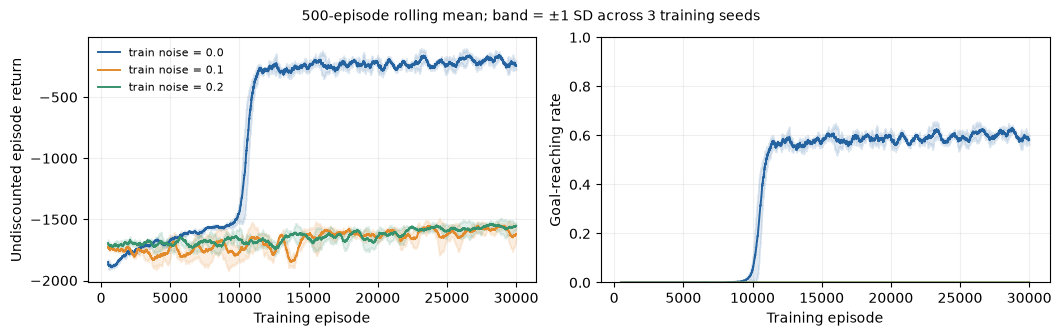

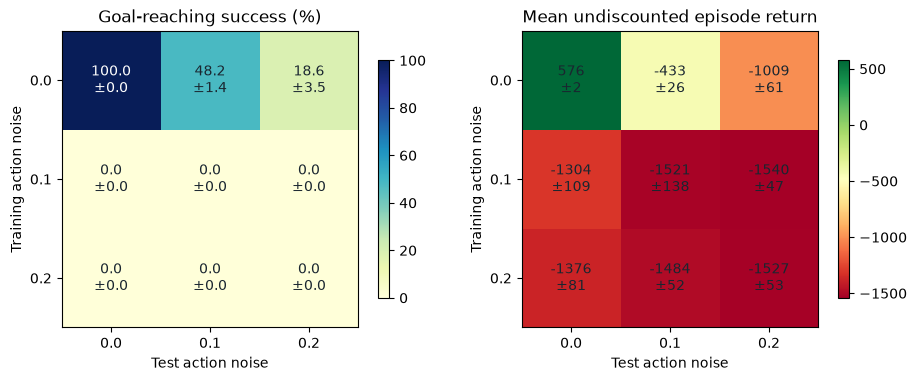

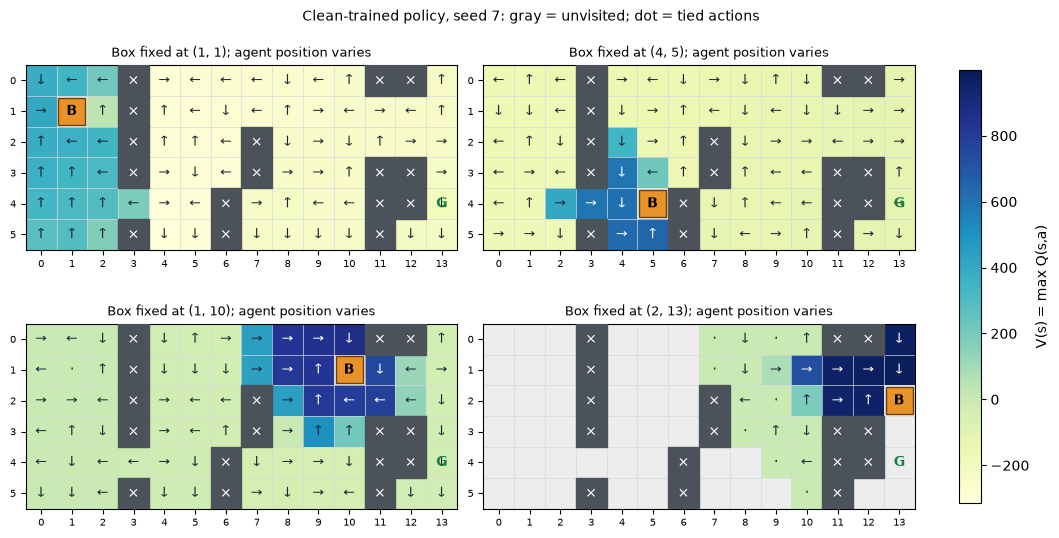

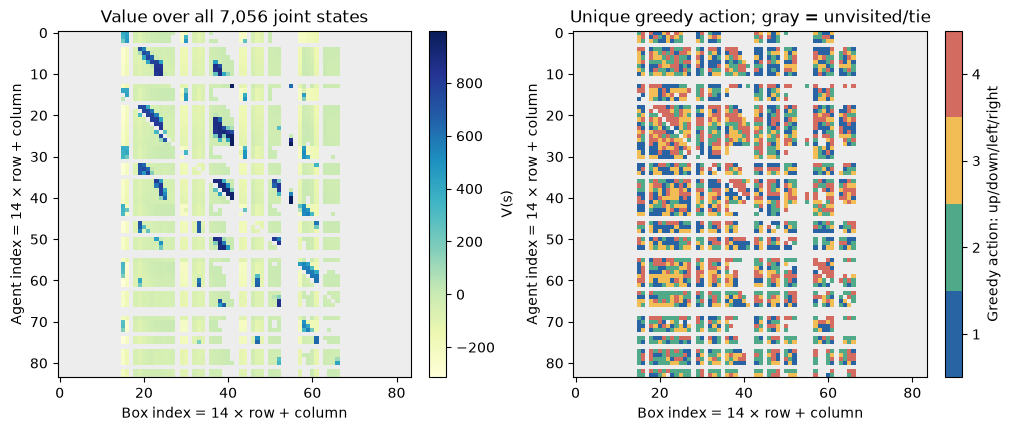

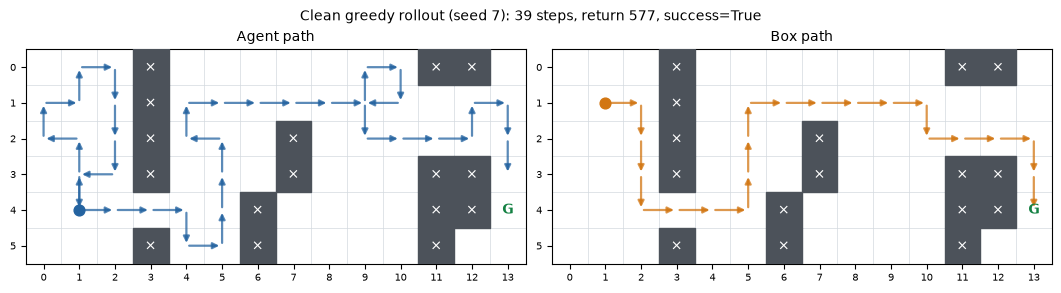

In [8]:
figures = make_figures(study, OUTPUT_DIR, animation=True)
for figure in figures:
    display(figure)
    plt.close(figure)

## 5. Action-Noise Results and Greedy Trajectory
Clean-trained policies achieve 100% success without test noise. Their success rates decrease to 48.22% at test noise 0.1 and 18.56% at test noise 0.2. Action substitutions near cliffs interrupt trajectories that succeed under deterministic execution.

Agents trained with noise 0.1 and 0.2 record no goal visits across 90,000 training episodes per setting and achieve zero success across the three test-noise levels. Their noise-free greedy evaluations end in timeout. Successful goal-reaching behavior did not emerge under these training settings.

Training success includes ε exploration and action noise, while evaluation removes ε exploration. The seed-7 clean-trained greedy policy completes the task in 39 primitive steps with an undiscounted return of 577. The following trajectory and animation show its actions, states, and rewards.

Success mean ± SD (%):
[[100.    48.22  18.56]
 [  0.     0.     0.  ]
 [  0.     0.     0.  ]]
[[0.   1.39 3.53]
 [0.   0.   0.  ]
 [0.   0.   0.  ]]
Mean return ± SD:
[[  575.67  -433.48 -1009.15]
 [-1304.33 -1521.25 -1540.45]
 [-1376.   -1484.13 -1527.18]]
[[  2.31  25.97  60.58]
 [108.58 138.29  46.73]
 [ 81.43  52.19  53.08]]
Random baseline: 0.0% success, -1403.62 mean return over 1,000 episodes
Clean seed-7 greedy rollout: 39 steps, return 577.0 success True
 t | state (agent row,col, box row,col) | action | reward
 0 | (4, 1, 1, 1)                       |      1 |    -18
 1 | (3, 1, 1, 1)                       |      1 |    -17
 2 | (2, 1, 1, 1)                       |      3 |    -18
 3 | (2, 0, 1, 1)                       |      1 |    -17
 4 | (1, 0, 1, 1)                       |      4 |    -16
 5 | (1, 1, 1, 2)                       |      1 |    -17
 6 | (0, 1, 1, 2)                       |      4 |    -16
 7 | (0, 2, 1, 2)                       |      2 |    -15
 8 | (1,

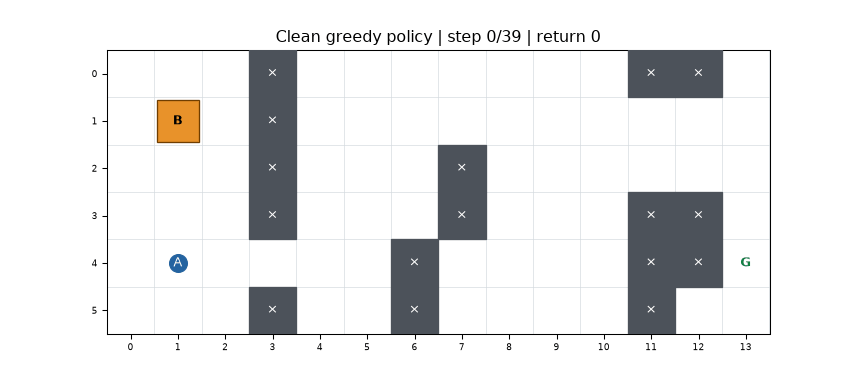

In [9]:
print('Success mean ± SD (%):')
print(np.round(100 * success_rate, 2))
print(np.round(100 * study['arrays']['success'].std(axis=0, ddof=1), 2))
print('Mean return ± SD:')
print(np.round(average_return, 2))
print(np.round(study['arrays']['mean_return'].std(axis=0, ddof=1), 2))
baseline = study['summary']['baseline']
print(f"Random baseline: {np.mean(baseline['success']):.1%} success, "
      f"{np.mean(baseline['returns']):.2f} mean return over 1,000 episodes")
rollout = study['summary']['rollout']
print('Clean seed-7 greedy rollout:', len(rollout['actions']), 'steps, return',
      sum(rollout['rewards']), 'success', rollout['success'])
print(' t | state (agent row,col, box row,col) | action | reward')
for t, (state, action, reward) in enumerate(zip(rollout['states'], rollout['actions'], rollout['rewards'])):
    print(f'{t:2d} | {str(state):34s} | {action:6d} | {reward:6.0f}')
display(Image(filename=str(OUTPUT_DIR / 'greedy_rollout.gif'), format='gif'))

## 6. Comparison of Exploration Strategies
The exploration study compares ε-greedy training with ε=0.1, UCB action selection, and greedy training with ε=0. All methods use the original reward, primitive actions, zero action noise, α=0.1, γ=0.99, and 30,000 training episodes per seed. The clean ε-greedy runs from the preceding experiment provide the ε-greedy results. Each policy is evaluated for 300 episodes per seed with exploration disabled.

UCB first selects actions that have not been tried in the current state. Once all actions have been sampled, it maximizes

$$Q(s,a)+20\sqrt{\frac{\ln(N(s)+1)}{N(s,a)}},$$

where $N(s,a)$ counts selections of action $a$ in state $s$, and $N(s)=\sum_aN(s,a)$. The exploration term is used for action selection; Q-values are updated using the original Q-learning target. All three strategies use random tie-breaking.

In [10]:
"""Bonus experiments: UCB exploration and sparse-reward semi-Markov Q-learning."""
from collections import deque
from pathlib import Path
import csv
import json
import time
import numpy as np
import matplotlib.pyplot as plt



class ExplorationAgent(RLAgent):
    """Change only training action selection; the TD update remains Q-learning."""
    def __init__(self, env, num_episodes, strategy='ucb', c=20.0, **kwargs):
        super().__init__(env, num_episodes, **kwargs)
        if strategy not in ['epsilon_greedy', 'ucb', 'greedy'] or c < 0:
            raise ValueError('Unknown exploration strategy or negative c.')
        self.strategy, self.c = strategy, c
        self.action_counts = {state: np.zeros(4, dtype=int) for state in self.q_table}

    def act(self, state, is_training=True, rng=None):
        rng = self.rng if rng is None else rng
        if not is_training or self.strategy == 'greedy':
            return super().act(state, is_training=False, rng=rng)
        if self.strategy == 'epsilon_greedy':
            return super().act(state, is_training=True, rng=rng)
        counts = self.action_counts[state]
        untried = np.flatnonzero(counts == 0)
        if len(untried):
            return self.action_space[int(rng.choice(untried))]
        values = np.array(list(self.q_table[state].values()))
        scores = values + self.c * np.sqrt(np.log(counts.sum() + 1) / counts)
        choices = np.flatnonzero(scores == scores.max())
        return self.action_space[int(rng.choice(choices))]

    def update(self, state, intended_action, reward, next_state, done):
        self.action_counts[state][self.action_space.index(intended_action)] += 1
        super().update(state, intended_action, reward, next_state, done)


def run_exploration_bonus(output_dir='results', episodes=30000,
                          seeds=(7, 17, 27), eval_episodes=300,
                          reference_study=None):
    """Clean, original-reward comparison. Reuse the identical epsilon reference."""
    output_dir = Path(output_dir)
    methods = ['epsilon_greedy', 'ucb', 'greedy']
    history = np.zeros((len(seeds), len(methods), episodes))
    success_history = np.zeros_like(history, dtype=bool)
    evaluation = np.zeros((len(seeds), len(methods), 2))
    rows, eval_records = [], {}
    for k, seed in enumerate(seeds):
        for j, method in enumerate(methods):
            if method == 'epsilon_greedy' and reference_study is not None:
                cfg = reference_study['summary']['config']
                assert cfg['episodes'] == episodes and cfg['seeds'] == list(seeds)
                history[k,j] = reference_study['arrays']['training_returns'][k,0]
                success_history[k,j] = reference_study['arrays']['training_success'][k,0]
                evaluation[k,j] = [reference_study['arrays']['success'][k,0,0],
                                   reference_study['arrays']['mean_return'][k,0,0]]
                source = 'identical mandatory clean-training run (reused)'
            else:
                agent = ExplorationAgent(CliffBoxGridWorld(), episodes,
                                         strategy=method, c=20, seed=seed)
                history[k,j] = agent.learn()
                success_history[k,j] = agent.training_success
                details = evaluate_details(agent, 0, eval_episodes,
                                           100000 + seed * 100)
                eval_records[f'{method}_seed{seed}'] = details
                evaluation[k,j] = [np.mean(details['success']), np.mean(details['returns'])]
                source = 'new independent training run'
            indices = np.flatnonzero(success_history[k,j])
            first = int(indices[0]+1) if len(indices) else None
            rows.append(dict(seed=seed, method=method,
                             first_success=first,
                             train_success_last2000=float(success_history[k,j,-2000:].mean()),
                             eval_success=float(evaluation[k,j,0]),
                             eval_return=float(evaluation[k,j,1]), source=source))
            print(f'Exploration: seed={seed}, {method}, first success={first}, '
                  f'greedy success={evaluation[k,j,0]:.1%}', flush=True)
    arrays = dict(returns=history, success=success_history, evaluation=evaluation)
    np.savez_compressed(output_dir/'bonus_exploration.npz', **arrays)
    summary = dict(methods=methods, seeds=list(seeds), episodes=episodes,
                   eval_episodes=eval_episodes, ucb_c=20,
                   epsilon_reference_reused=reference_study is not None, rows=rows)
    (output_dir/'bonus_exploration.json').write_text(json.dumps(summary, indent=2))
    (output_dir/'bonus_exploration_evaluation.json').write_text(json.dumps(eval_records))
    with (output_dir/'bonus_exploration.csv').open('w', newline='') as file:
        writer=csv.DictWriter(file, fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    return dict(arrays=arrays, summary=summary)




In [11]:
import json
RECOMPUTE_BONUS = False
exploration_files = [OUTPUT_DIR/'bonus_exploration.npz', OUTPUT_DIR/'bonus_exploration.json']
if RECOMPUTE_BONUS or not all(path.exists() for path in exploration_files):
    exploration_bonus = run_exploration_bonus(OUTPUT_DIR, reference_study=study)
else:
    exploration_bonus = {'arrays':dict(np.load(exploration_files[0])),
                         'summary':json.loads(exploration_files[1].read_text())}
    assert exploration_bonus['summary']['episodes'] == 30000
    assert exploration_bonus['summary']['seeds'] == [7,17,27]
    assert exploration_bonus['summary']['ucb_c'] == 20
    print('Reusing completed, recorded exploration experiments; set RECOMPUTE_BONUS=True to retrain.')
print('method | seed | first goal episode | greedy success | mean original return')
for row in exploration_bonus['summary']['rows']:
    print(row['method'], row['seed'], row['first_success'],
          f"{row['eval_success']:.1%}", f"{row['eval_return']:.2f}", sep=' | ')
ev = exploration_bonus['arrays']['evaluation']
for j, method in enumerate(exploration_bonus['summary']['methods']):
    print(f"{method}: greedy success {ev[:,j,0].mean():.1%} "
          f"± {ev[:,j,0].std(ddof=1):.1%} across seeds")

Reusing completed, recorded exploration experiments; set RECOMPUTE_BONUS=True to retrain.
method | seed | first goal episode | greedy success | mean original return
epsilon_greedy | 7 | 9131 | 100.0% | 577.00
ucb | 7 | 5106 | 100.0% | 577.00
greedy | 7 | 5127 | 100.0% | 577.00
epsilon_greedy | 17 | 8038 | 100.0% | 577.00
ucb | 17 | 5294 | 100.0% | 577.00
greedy | 17 | 4701 | 100.0% | 577.00
epsilon_greedy | 27 | 6285 | 100.0% | 573.00
ucb | 27 | 5031 | 100.0% | 577.00
greedy | 27 | 4735 | 100.0% | 577.00
epsilon_greedy: greedy success 100.0% ± 0.0% across seeds
ucb: greedy success 100.0% ± 0.0% across seeds
greedy: greedy success 100.0% ± 0.0% across seeds


## 7. Sparse-Reward Learning with Push Options and Replay
The sparse experiment uses reward 1000 when the box reaches the original goal and 0 for every other transition. The map, initial positions, transition rules, and 100-primitive-step episode limit are retained.

The hierarchical learner uses hand-designed safe-push options. For each feasible push direction, local BFS finds a safe path that positions the agent on the required side of the box, followed by one push. The options use the map and box-boundary rules, while the high-level Q-table learns which push direction to select. Every primitive action is executed through the environment and counted toward the episode limit. In states with no feasible push, the agent walks safely until timeout.

For an option lasting $k$ primitive steps, the semi-Markov Q-learning target is

$$y=\sum_{i=0}^{k-1}\gamma^ir_i+(1-d)\gamma^k\max_oQ(s',o).$$

The replay variant performs 10 backward update passes over the option transitions of each successful training episode.

Four methods are compared: primitive ε-greedy Q-learning, random selection of safe-push options, option Q-learning, and option Q-learning with successful-trajectory replay. Each method trains for 5,000 episodes using seeds 7, 17, and 27, followed by 300 evaluation episodes per seed. Learned policies are evaluated greedily; the random-options baseline continues to select options uniformly. Environment interactions and replay updates are recorded for each method.

In [12]:
def sparse_reward(env):
    """The only reward used by all sparse learners and sparse evaluations."""
    return 1000.0 if np.array_equal(env.box_pos, env.goal_pos) else 0.0


class SparsePrimitiveAgent(RLAgent):
    """Ordinary epsilon-greedy Q-learning with only 0/1000 rewards."""
    def learn(self, action_noise=0.0):
        if action_noise != 0:
            raise ValueError('The bonus isolates sparse learning at action noise zero.')
        rewards = []
        self.training_success, self.training_lengths = [], []
        for _ in range(self.num_episodes):
            state, done, total = self.env.reset(), False, 0.0
            while not done:
                action = self.act(state)
                nxt, _, done, _ = self.env.step(action)
                reward = sparse_reward(self.env)
                self.update(state, action, reward, nxt, done)
                self.visits[state] += 1
                state, total = nxt, total + reward
            rewards.append(total)
            self.training_success.append(total == 1000)
            self.training_lengths.append(self.env.timesteps)
        return rewards


class SafePushOptions:
    """Hand-designed skills, NOT a global box-to-goal planner.

    A skill finds a shortest safe AGENT path to the opposite side of the box,
    then performs exactly one push. BFS treats cliffs and the box as obstacles.
    Skills filter cliff/boundary pushes. They never inspect goal distance.
    The original environment executes and counts EVERY primitive action.
    """
    def __init__(self):
        self.cache = {}
        self.cliffs = set()
        for (r0, col), (r1, _) in CliffBoxGridWorld.danger_region:
            self.cliffs.update((row, col) for row in range(r0, r1+1))
        self.forces = {a: tuple(map(int, force)) for a, force in CliffBoxGridWorld.forces.items()}

    def safe(self, pos):
        return 0 <= pos[0] < 6 and 0 <= pos[1] < 14 and pos not in self.cliffs

    def path(self, start, target, box):
        if not self.safe(target) or target == box:
            return None
        queue = deque([(start, [])]); seen = {start}
        while queue:
            position, actions = queue.popleft()
            if position == target:
                return actions
            for action, (dr, dc) in self.forces.items():
                nxt = (position[0]+dr, position[1]+dc)
                if self.safe(nxt) and nxt != box and nxt not in seen:
                    seen.add(nxt);queue.append((nxt, actions+[action]))
        return None

    def available(self, state):
        if state in self.cache:
            return self.cache[state]
        agent, box = tuple(state[:2]), tuple(state[2:])
        options = {}
        for action, (dr, dc) in self.forces.items():
            dest, stand = (box[0]+dr, box[1]+dc), (box[0]-dr, box[1]-dc)
            # Match the supplied box's hard boundaries, rather than generic clipping.
            if not (1 <= dest[0] <= 4 and 1 <= dest[1] <= 13 and self.safe(dest)):
                continue
            path = self.path(agent, stand, box)
            if path is not None:
                options[action] = tuple(path+[action])
        self.cache[state] = options
        return options

    def finish_dead_end(self, env):
        """Use real safe walking steps until the original 100-step timeout."""
        done = False
        while not done:
            agent, box = tuple(map(int, env.agent_pos)), tuple(map(int, env.box_pos))
            for action, (dr, dc) in self.forces.items():
                raw = (agent[0]+dr, agent[1]+dc)
                nxt = (max(0,min(5,raw[0])), max(0,min(13,raw[1])))
                if self.safe(nxt) and nxt != box:
                    _, _, done, _ = env.step(action)
                    break
            else:
                raise RuntimeError('No safe primitive fallback in a dead-end state.')


class SparseOptionAgent:
    """Semi-Markov Q-learning over generic push skills; optional success replay."""
    def __init__(self, env, num_episodes, seed=7, replay_passes=10,
                 random_options=False, alpha=.1, gamma=.99, epsilon=.1):
        self.env, self.num_episodes = env, num_episodes
        self.rng = np.random.default_rng(seed)
        self.skills = SafePushOptions()
        self.q_table, self.option_counts = {}, {}
        self.alpha, self.gamma, self.epsilon = alpha, gamma, epsilon
        self.replay_passes, self.random_options = replay_passes, random_options
        self.training_success, self.training_lengths = [], []
        self.replay_updates, self.online_updates = 0, 0

    def values(self, state, create=True):
        if state not in self.q_table:
            values = {a:0.0 for a in self.skills.available(state)}
            if not create:
                return values
            self.q_table[state] = values
        return self.q_table[state]

    def select(self, state, training, rng):
        values = self.values(state, create=training)
        if not values:
            return None
        if self.random_options or (training and rng.random() < self.epsilon):
            return int(rng.choice(list(values)))
        best = max(values.values())
        return int(rng.choice([a for a,v in values.items() if v == best]))

    def update_option(self, state, option, discounted_reward, nxt, done, duration):
        target = discounted_reward
        if not done:
            target += self.gamma**duration * max(self.values(nxt).values(), default=0.0)
        current = self.values(state)[option]
        self.q_table[state][option] += self.alpha*(target-current)

    def episode(self, training=True, rng=None):
        rng = self.rng if rng is None else rng
        state, done = self.env.reset(), False
        trajectory, primitive_actions = [], []
        total, option_choices = 0.0, 0
        while not done:
            option = self.select(state, training, rng)
            if option is None:
                self.skills.finish_dead_end(self.env)
                break
            discounted, duration = 0.0, 0
            for action in self.skills.available(state)[option]:
                nxt, _, done, _ = self.env.step(action)
                reward = sparse_reward(self.env)
                discounted += self.gamma**duration * reward
                total += reward; duration += 1;primitive_actions.append(action)
                if done:
                    break
            transition = (state, option, discounted, nxt, done, duration)
            if training and not self.random_options:
                self.update_option(*transition);self.online_updates += 1
            trajectory.append(transition)
            option_choices += 1;state = nxt
        if training and total == 1000 and not self.random_options:
            # Repeat only genuine observed transitions; no demonstrations or relabeling.
            for _ in range(self.replay_passes):
                for transition in reversed(trajectory):
                    self.update_option(*transition);self.replay_updates += 1
        return dict(success=total == 1000, returns=total,
                    lengths=self.env.timesteps, options=option_choices,
                    actions=primitive_actions)

    def learn(self):
        records = []
        for _ in range(self.num_episodes):
            result=self.episode(training=True);records.append(result['returns'])
            self.training_success.append(result['success'])
            self.training_lengths.append(result['lengths'])
        return records


def evaluate_sparse(agent, total_run=300, seed=10007):
    """Freeze the learner; evaluate original starts/horizon with sparse rewards."""
    rng=np.random.default_rng(seed)
    records={'success':[], 'returns':[], 'lengths':[]}
    if isinstance(agent, SparseOptionAgent):
        # Unseen states use temporary zeros, never new Q entries during evaluation.
        for _ in range(total_run):
            result=agent.episode(training=False, rng=rng)
            for key in records: records[key].append(result[key])
    else:
        env=CliffBoxGridWorld()
        for _ in range(total_run):
            state,done,total=env.reset(),False,0.0
            while not done:
                action=agent.act(state,is_training=False,rng=rng)
                state,_,done,_=env.step(action)
                total += sparse_reward(env)
            records['success'].append(total==1000)
            records['returns'].append(total)
            records['lengths'].append(env.timesteps)
    assert np.isclose(np.mean(records['returns']),1000*np.mean(records['success']))
    return records


def run_sparse_bonus(output_dir='results', episodes=5000,
                     seeds=(7,17,27), eval_episodes=300):
    """Ablations isolate skill prior and reverse replay. Equal episode/horizon caps."""
    output_dir=Path(output_dir)
    methods=['primitive_epsilon','random_options','option_q','option_q_replay']
    returns=np.zeros((len(seeds),len(methods),episodes))
    lengths=np.zeros_like(returns,dtype=int)
    evaluation=np.zeros((len(seeds),len(methods),3))
    rows, eval_records, representative = [],{},{}
    for k,seed in enumerate(seeds):
        for j,method in enumerate(methods):
            if method=='primitive_epsilon':
                agent=SparsePrimitiveAgent(CliffBoxGridWorld(),episodes,seed=seed)
            else:
                agent=SparseOptionAgent(CliffBoxGridWorld(),episodes,seed=seed,
                     random_options=method=='random_options',
                     replay_passes=10 if method=='option_q_replay' else 0)
            returns[k,j]=agent.learn()
            lengths[k,j]=agent.training_lengths
            details=evaluate_sparse(agent,eval_episodes,200000+seed*100)
            eval_records[f'{method}_seed{seed}']=details
            evaluation[k,j]=[np.mean(details[x]) for x in ['success','returns','lengths']]
            firsts=np.flatnonzero(returns[k,j]>0)
            first=int(firsts[0]+1) if len(firsts) else None
            first_steps=int(lengths[k,j,:first].sum()) if first else None
            row=dict(seed=seed,method=method,first_success=first,
                     interactions_to_first_success=first_steps,
                     total_interactions=int(lengths[k,j].sum()),
                     train_success_last1000=float((returns[k,j,-1000:]>0).mean()),
                     eval_success=float(evaluation[k,j,0]),
                     eval_return=float(evaluation[k,j,1]),
                     eval_steps=float(evaluation[k,j,2]),
                     online_updates=getattr(agent,'online_updates',int(lengths[k,j].sum())),
                     replay_updates=getattr(agent,'replay_updates',0))
            rows.append(row)
            if k==0:
                representative[method]=agent
            print(f'Sparse: seed={seed}, {method}, first={first}, '
                  f'eval success={evaluation[k,j,0]:.1%}',flush=True)
    arrays=dict(returns=returns,lengths=lengths,evaluation=evaluation)
    np.savez_compressed(output_dir/'bonus_sparse.npz',**arrays)
    summary=dict(methods=methods,seeds=list(seeds),episodes=episodes,
                 eval_episodes=eval_episodes,replay_passes=10,rows=rows,
                 priors='Safe local BFS positioning + single safe push; no global box route, '
                        'no goal-distance features, no demonstrations, no intermediate reward.')
    (output_dir/'bonus_sparse.json').write_text(json.dumps(summary,indent=2))
    (output_dir/'bonus_sparse_evaluation.json').write_text(json.dumps(eval_records))
    with (output_dir/'bonus_sparse.csv').open('w',newline='') as file:
        writer=csv.DictWriter(file,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    # Replay the predeclared seed-7 learned hierarchy for the saved demonstration.
    agent=representative['option_q_replay']
    result=agent.episode(training=False,rng=np.random.default_rng(9007))
    env=CliffBoxGridWorld();state=env.reset();states=[state];rewards=[]
    for action in result['actions']:
        state,_,done,_=env.step(action);states.append(state);rewards.append(sparse_reward(env))
    rollout=dict(states=states,actions=result['actions'],rewards=rewards,success=result['success'])
    (output_dir/'bonus_sparse_rollout.json').write_text(json.dumps(rollout,indent=2))
    np.savez_compressed(output_dir/'bonus_sparse_policy_seed7.npz',
                       states=np.array(list(agent.q_table)),
                       q=np.array([[values.get(a,np.nan) for a in [1,2,3,4]]
                                   for values in agent.q_table.values()]))
    return dict(arrays=arrays,summary=summary,rollout=rollout)


def plot_bonus_results(exploration, sparse, output_dir='results'):
    output_dir=Path(output_dir)
    fig,axes=plt.subplots(1,2,figsize=(10.5,3.0),layout='constrained')
    colors=['#2463a0','#e38b2c','#37926e','#a45ca5']
    for ax,result,key,window,title in [(axes[0],exploration,'success',500,'Original reward: exploration'),
                                     (axes[1],sparse,'returns',100,'Sparse reward: skill/replay ablation')]:
        for j,method in enumerate(result['summary']['methods']):
            history=result['arrays'][key][:,j]
            if key=='returns':history=history/1000
            smooth=np.array([np.convolve(row,np.ones(window)/window,mode='valid') for row in history])
            mean,sd=smooth.mean(0),smooth.std(0,ddof=1)
            x=np.arange(window,history.shape[1]+1)
            ax.plot(x,mean,label=method,color=colors[j],lw=1.3)
            ax.fill_between(x,np.clip(mean-sd,0,1),np.clip(mean+sd,0,1),color=colors[j],alpha=.12)
        ax.set(xlabel='Training episode',ylabel='Goal-reaching rate',ylim=(-.02,1.02),title=title)
        ax.legend(fontsize=6.5,frameon=False);ax.grid(alpha=.2)
    fig.suptitle('Means across 3 seeds; bands = ±1 sample SD',fontsize=9)
    fig.savefig(output_dir/'bonus_learning_curves.png',dpi=200,bbox_inches='tight')
    return fig

Reusing completed, recorded sparse experiments; set RECOMPUTE_BONUS=True to retrain.
method | seed | first success | greedy success | steps | interactions | extra replay updates
primitive_epsilon | 7 | None | 0.0% | 19.6 | 104491 | 0
random_options | 7 | 570 | 0.0% | 100.0 | 499898 | 0
option_q | 7 | 1155 | 0.0% | 100.0 | 499999 | 0
option_q_replay | 7 | 1155 | 100.0% | 45.0 | 319727 | 884570
primitive_epsilon | 17 | None | 0.0% | 20.9 | 103124 | 0
random_options | 17 | 1386 | 0.0% | 100.0 | 499999 | 0
option_q | 17 | 3454 | 0.0% | 100.0 | 499979 | 0
option_q_replay | 17 | 3454 | 100.0% | 39.0 | 429353 | 354030
primitive_epsilon | 27 | None | 0.0% | 20.7 | 103609 | 0
random_options | 27 | 626 | 0.0% | 100.0 | 499969 | 0
option_q | 27 | 2394 | 0.0% | 100.0 | 499967 | 0
option_q_replay | 27 | 2394 | 100.0% | 43.0 | 387034 | 570740
primitive_epsilon: success=0.00% ±0.00%; mean sparse return=0.00
random_options: success=0.00% ±0.00%; mean sparse return=0.00
option_q: success=0.00% ±0.00%; 

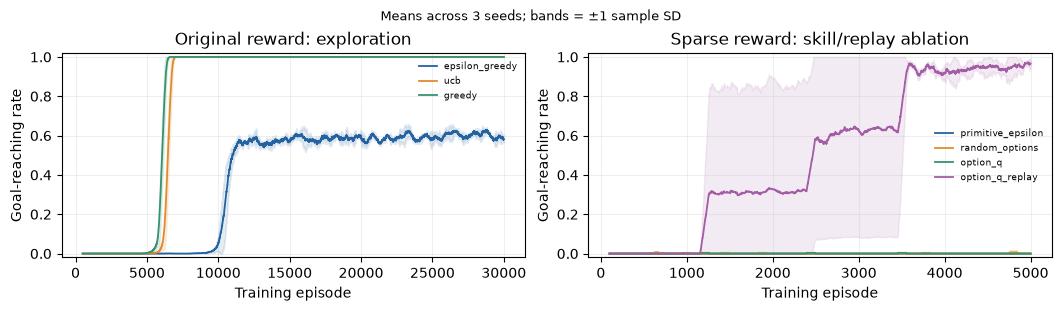

Seed-7 learned sparse rollout: 45 steps, 1000.0 return, success= True
Reward support: [0.0, 1000.0]
Sparse reward and primitive-step horizon checks passed.


In [13]:
sparse_files = [OUTPUT_DIR/'bonus_sparse.npz', OUTPUT_DIR/'bonus_sparse.json',
                OUTPUT_DIR/'bonus_sparse_rollout.json']
if RECOMPUTE_BONUS or not all(path.exists() for path in sparse_files):
    sparse_bonus = run_sparse_bonus(OUTPUT_DIR)
else:
    sparse_bonus = {'arrays':dict(np.load(sparse_files[0])),
                    'summary':json.loads(sparse_files[1].read_text()),
                    'rollout':json.loads(sparse_files[2].read_text())}
    assert sparse_bonus['summary']['episodes'] == 5000
    assert sparse_bonus['summary']['seeds'] == [7,17,27]
    assert sparse_bonus['summary']['replay_passes'] == 10
    print('Reusing completed, recorded sparse experiments; set RECOMPUTE_BONUS=True to retrain.')
print('method | seed | first success | greedy success | steps | interactions | extra replay updates')
for row in sparse_bonus['summary']['rows']:
    print(row['method'], row['seed'], row['first_success'],
          f"{row['eval_success']:.1%}", f"{row['eval_steps']:.1f}",
          row['total_interactions'], row['replay_updates'], sep=' | ')
ev = sparse_bonus['arrays']['evaluation']
assert np.allclose(ev[:,:,1], 1000*ev[:,:,0])
for j, method in enumerate(sparse_bonus['summary']['methods']):
    print(f"{method}: success={ev[:,j,0].mean():.2%} ±{ev[:,j,0].std(ddof=1):.2%}; "
          f"mean sparse return={ev[:,j,1].mean():.2f}")
figure = plot_bonus_results(exploration_bonus, sparse_bonus, OUTPUT_DIR)
display(figure); plt.close(figure)
print('Seed-7 learned sparse rollout:', len(sparse_bonus['rollout']['actions']), 'steps,',
      sum(sparse_bonus['rollout']['rewards']), 'return, success=',sparse_bonus['rollout']['success'])
print('Reward support:', sorted(set(sparse_bonus['rollout']['rewards'])))
assert set(sparse_bonus['rollout']['rewards']) <= {0.,1000.}
assert len(sparse_bonus['rollout']['actions']) <= 100
print('Sparse reward and primitive-step horizon checks passed.')

## 8. Discussion of Experimental Results
All three exploration strategies achieved 100% final success under noise-free evaluation. The median first-success episodes were 8,038 for ε-greedy, 5,106 for UCB, and 4,735 for greedy training. UCB accelerated goal discovery relative to ε-greedy, while greedy training discovered successful trajectories earliest. Optimistic zero initialization and random tie-breaking provided exploration even with ε=0: negative updates made previously untried actions more attractive than actions already associated with negative returns.

Under purely sparse rewards, primitive Q-learning, random safe options, and option Q-learning without replay each achieved 0% final evaluation success. Option Q-learning with successful-trajectory replay achieved 100% success across three training seeds, completing all 900 evaluation episodes. The resulting policies required an average of 42.3 primitive steps and obtained an undiscounted return of 1000 per episode.

The learned option variants discovered their first successful trajectories at the same episodes—1,155, 3,454, and 2,394—with and without replay. Their subsequent performance differed substantially. Backward replay propagated the terminal reward through the successful option sequence, allowing the learner to retain and repeatedly execute effective behavior. Safe-push options supplied structured exploration, and replay made successful experience more effective for learning. Together, these components produced reliable performance while retaining the original map, initial state, 100-step limit, and strictly 0/1000 reward scheme.